# 01 - Exploratory Data Analysis

> Research prototype only. The dataset is simulated and labels are experimental proxies. No result here validates field deployment or early-warning lead time.

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from src.data_loader import load_config, load_raw_data
from src.data_validation import validate_target

config = load_config()
frame = load_raw_data(config=config)
target = validate_target(frame, config)
print('shape:', frame.shape)

shape: (2337, 28)


## 1. Schema, missing values and duplicates

In [2]:
frame_info = pd.DataFrame({
    'dtype': frame.dtypes.astype(str),
    'missing': frame.isna().sum(),
    'unique': frame.nunique(),
})
frame_info

,dtype,missing,unique
CircFlow,float64,0,1843
FRate,float64,0,1892
FDensity,float64,0,838
SMSpeed,float64,0,1697
BDepth,float64,0,1393
BSize,float64,0,2
MVis,float64,0,838
FPress,float64,0,1497
DPPress,float64,0,1592
CPress,int64,0,1


In [3]:
print('Duplicate rows:', frame.duplicated().sum())
frame.describe().T

Duplicate rows: 5


,count,mean,std,min,25%,50%,75%,max
CircFlow,2337.0,0.954872,2.013096e-02,0.000000,0.952941,0.953155,0.957909,0.965908
FRate,2337.0,-1.633996,9.329725e-01,-3.012529,-2.969717,-0.954970,-0.952929,0.000000
FDensity,2337.0,77.009714,3.102157e+00,0.000000,76.493310,78.547070,78.547070,78.547070
SMSpeed,2337.0,-0.029816,4.427132e-02,-0.177619,-0.047434,-0.005481,0.000000,0.000000
BDepth,2337.0,12643.593188,2.617838e+02,0.000000,12641.760000,12645.620000,12655.210000,12665.350000
BSize,2337.0,12.244758,2.534001e-01,0.000000,12.250000,12.250000,12.250000,12.250000
MVis,2337.0,9.789161,4.184662e-01,0.000000,9.717114,10.000450,10.000450,10.000450
FPress,2337.0,7221.057582,8.581521e+02,6157.120000,6157.255000,7263.528000,8223.024000,8224.046000
DPPress,2337.0,1646.643925,9.625912e+01,1302.940000,1683.405000,1683.492000,1688.603000,1730.271000
CPress,2337.0,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000


## 2. Target verification and class balance

`ActiveGL` is a continuous pit gain/loss indicator. The sign change from pit loss to pit gain coincides with the kick depth documented in the source paper. The resulting label is an experimental proxy, not authoritative ground truth.

Rule: ActiveGL > 0 bbl (pit gain rather than pit loss)
Onset index: 1501 depth (ft): 12650.15
Positives: 836 Negatives: 1501
Warnings: ["No authoritative kick label is supplied by the dataset. Labels are an EXPERIMENTAL PROXY from 'ActiveGL' and must be confirmed by a drilling supervisor before any research claim is made."]


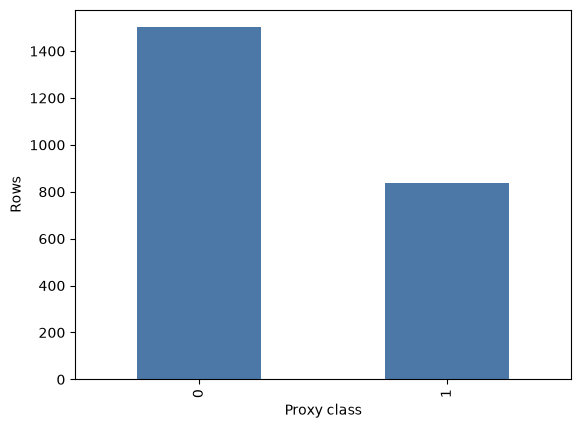

In [4]:
print('Rule:', target.rule)
print('Onset index:', target.onset_index, 'depth (ft):', target.onset_depth)
print('Positives:', target.n_positive, 'Negatives:', target.n_negative)
print('Warnings:', target.warnings)
ax = target.labels.value_counts().sort_index().plot(kind='bar', color='#4c78a8')
ax.set_xlabel('Proxy class'); ax.set_ylabel('Rows'); plt.show()

## 3. Feature distributions and correlation structure

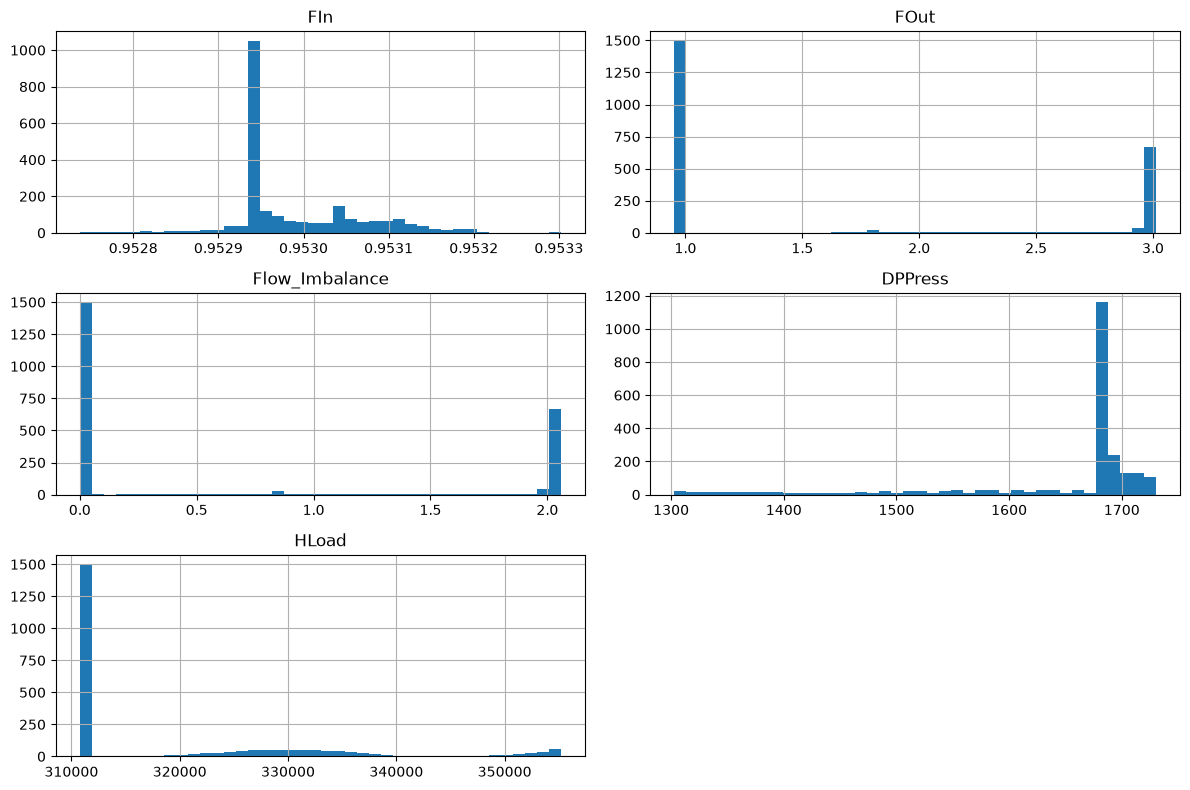

In [5]:
from src.feature_engineering import add_engineered_features
featured = add_engineered_features(frame, config)
featured[['FIn', 'FOut', 'Flow_Imbalance', 'DPPress', 'HLoad']].hist(bins=40, figsize=(12, 8))
plt.tight_layout(); plt.show()

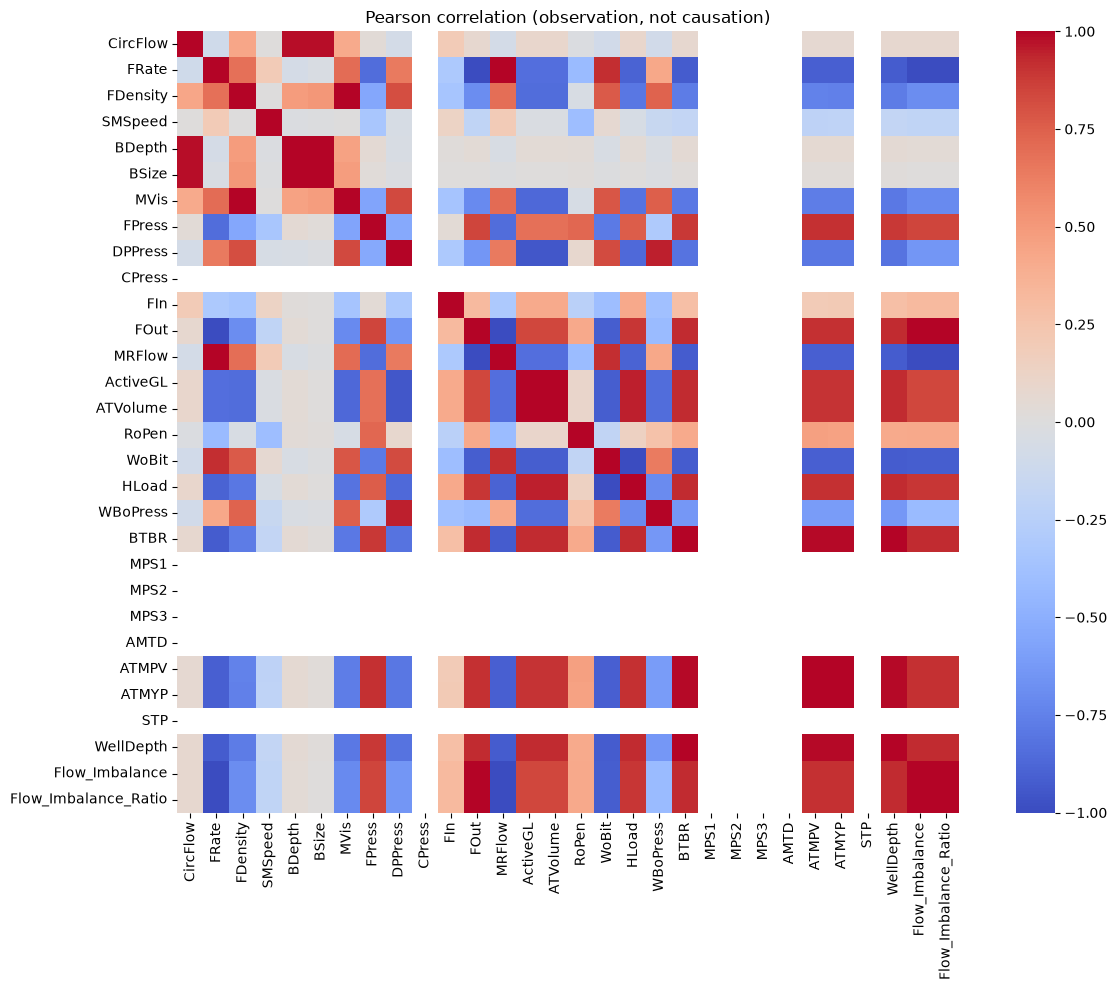

In [6]:
numeric = featured.select_dtypes(include='number')
plt.figure(figsize=(13, 10))
sns.heatmap(numeric.corr(), cmap='coolwarm', center=0, vmin=-1, vmax=1, square=True)
plt.title('Pearson correlation (observation, not causation)')
plt.tight_layout(); plt.show()

## 4. Parameter behaviour by proxy class

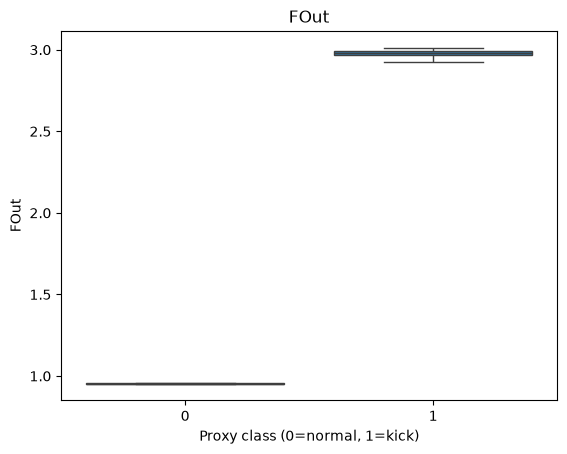

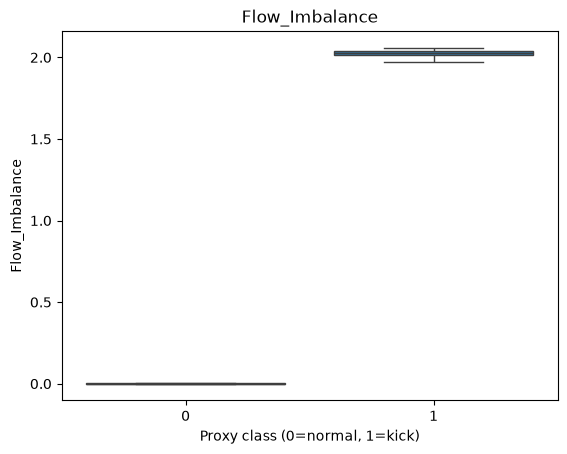

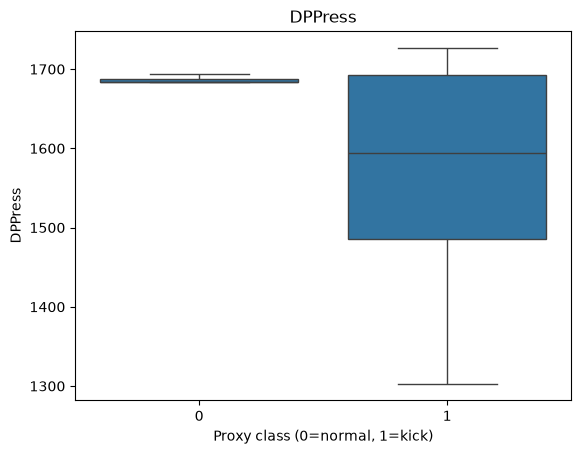

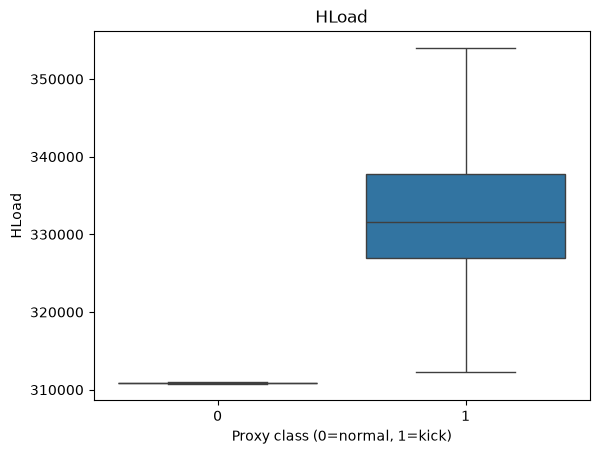

In [7]:
for column in ['FOut', 'Flow_Imbalance', 'DPPress', 'HLoad']:
    sns.boxplot(x=target.labels.to_numpy(), y=featured[column], showfliers=False)
    plt.xlabel('Proxy class (0=normal, 1=kick)')
    plt.title(column)
    plt.show()

## 5. Flow, pressure and pit-gain relationships

The identity `MRFlow = FIn - FOut` justifies `Flow_Imbalance = FOut - FIn`. A positive imbalance means return flow exceeds input flow, consistent with an influx.

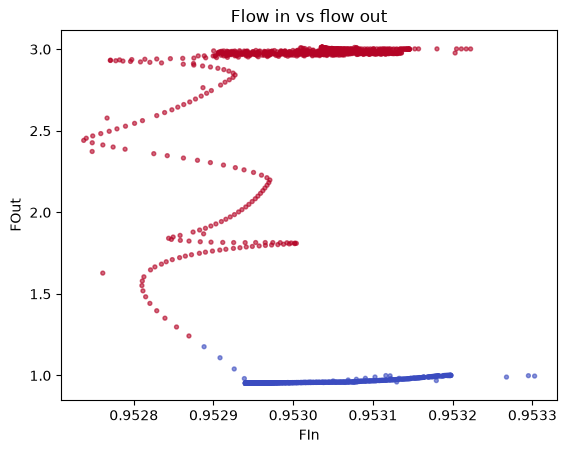

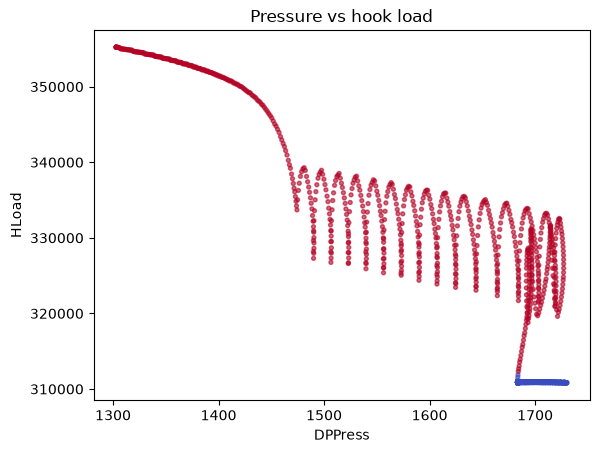

In [8]:
plt.scatter(featured['FIn'], featured['FOut'], c=target.labels, s=8, alpha=0.6, cmap='coolwarm')
plt.xlabel('FIn'); plt.ylabel('FOut'); plt.title('Flow in vs flow out'); plt.show()
plt.scatter(featured['DPPress'], featured['HLoad'], c=target.labels, s=8, alpha=0.6, cmap='coolwarm')
plt.xlabel('DPPress'); plt.ylabel('HLoad'); plt.title('Pressure vs hook load'); plt.show()

## 6. Reproduce published figures and report

In [9]:
from src.eda import generate_figures, write_eda_report
figures = generate_figures(frame, target, config)
report = write_eda_report(frame, target, config, figures)
print(report)

C:\Users\dnyak\OneDrive\Fifth_year_project\reports\eda_report.md
